In [2]:
from pathlib import Path
from datasets import load_dataset

ds = load_dataset("electricsheepafrica/africa-synth-telecom-telecom-credit-scoring-data-nigeria")
print(ds)
split = list(ds.keys())[0]
df = ds[split].to_pandas()
Path("data/raw").mkdir(parents=True, exist_ok=True)
df.to_csv("data/raw/telecom.csv", index=False)
print("Split :", split, "| dimensions :", df.shape)
print(df.dtypes)
print(df.head())

DatasetDict({
    train: Dataset({
        features: ['customer_id', 'phone_number', 'operator', 'assessment_date', 'credit_score', 'credit_rating', 'tenure_months', 'avg_monthly_spend_ngn', 'recharge_frequency_per_month', 'payment_consistency_score', 'late_payment_count', 'account_type', 'loan_eligibility', 'max_loan_amount_ngn', 'default_risk'],
        num_rows: 500000
    })
})
Split : train | dimensions : (500000, 15)
customer_id                             object
phone_number                            object
operator                                object
assessment_date                 datetime64[ns]
credit_score                             int64
credit_rating                           object
tenure_months                            int64
avg_monthly_spend_ngn                  float64
recharge_frequency_per_month             int64
payment_consistency_score              float64
late_payment_count                       int64
account_type                            object
loan_elig

# 01 - Exploration du dataset (EDA)
Tâche 2 (Choula) : explorer *Telecom Credit Scoring Data (Nigeria)* et documenter le jeu de données.

Ce notebook **ne suppose aucun nom de colonne** hormis la cible `default_risk` (donnée par l'énoncé). Il détecte les types lui-même et écrit un résumé chiffré dans `docs/eda_resume.md` et `reports/eda_summary.json`.

Rappel de l'énoncé : 500 000 lignes, 15 colonnes ; variables citées : ancienneté (`tenure_months`), dépenses moyennes, fréquence de recharge, cohérence des paiements, nombre de retards.

In [3]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

TARGET = "default_risk"
ROOT = Path("..") if Path("../data").exists() else Path(".")
CANDIDATES = [ROOT / "data/raw/telecom_credit_scoring_data.csv",
              ROOT / "data/raw/telecom.csv",
              ROOT / "data/raw/telecom_credit_scoring.csv",
              ROOT / "data/raw/telecom_credit_scoring.parquet"]
DATA_PATH = next((p for p in CANDIDATES if p.exists()), None)
assert DATA_PATH is not None, f"Dataset introuvable. Chemins essayés : {[str(p) for p in CANDIDATES]}"
FIG = ROOT / "reports/figures"; FIG.mkdir(parents=True, exist_ok=True)
(ROOT / "docs").mkdir(exist_ok=True)
print("Fichier utilisé :", DATA_PATH)

Fichier utilisé : data/raw/telecom.csv


## 1. Chargement et structure

In [4]:
df = pd.read_parquet(DATA_PATH) if DATA_PATH.suffix == ".parquet" else pd.read_csv(DATA_PATH)
print("Dimensions :", df.shape)
print(f"Mémoire : {df.memory_usage(deep=True).sum() / 1e6:.1f} Mo")
assert TARGET in df.columns, f"La cible '{TARGET}' est absente. Colonnes : {list(df.columns)}"
display(df.dtypes.to_frame("dtype"))
display(df.head())

Dimensions : (500000, 15)
Mémoire : 200.8 Mo


,dtype
customer_id,object
phone_number,int64
operator,object
assessment_date,object
credit_score,int64
credit_rating,object
tenure_months,int64
avg_monthly_spend_ngn,float64
recharge_frequency_per_month,int64
payment_consistency_score,float64


,customer_id,phone_number,operator,assessment_date,credit_score,credit_rating,tenure_months,avg_monthly_spend_ngn,recharge_frequency_per_month,payment_consistency_score,late_payment_count,account_type,loan_eligibility,max_loan_amount_ngn,default_risk
0,CUST7884214,2348188064475,9mobile,2025-09-30,766,good,47,38033.69,19,0.61,1,prepaid,True,62311.73,low
1,CUST9262918,2347037995775,MTN,2025-09-30,508,fair,51,4681.59,6,0.60,1,prepaid,False,0.00,low
2,CUST2670942,2348177270309,9mobile,2025-09-30,1000,excellent,114,37461.29,24,0.12,2,prepaid,True,47919.34,medium
3,CUST3837926,2348059892823,Glo,2025-09-30,1000,excellent,118,43504.04,29,0.78,2,prepaid,True,104373.86,low
4,CUST1683850,2348104277310,MTN,2025-09-30,945,excellent,105,41622.46,11,0.48,1,postpaid,True,41723.86,low


## 2. Qualité des données
Valeurs manquantes, doublons, colonnes constantes, colonnes de type identifiant.

In [5]:
n = len(df)
quality = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "manquants": df.isna().sum(),
    "% manquants": (df.isna().mean() * 100).round(3),
    "valeurs_uniques": df.nunique(dropna=True),
})
display(quality)
n_dup = int(df.duplicated().sum())
constantes = quality.index[quality["valeurs_uniques"] <= 1].tolist()
ident_like = [c for c in df.columns if c != TARGET and df[c].nunique() / n >= 0.95 and not pd.api.types.is_float_dtype(df[c])]
print("Lignes dupliquées :", n_dup)
print("Colonnes constantes :", constantes)
print("Colonnes de type identifiant (>= 95 % de valeurs uniques) :", ident_like)
print("Lignes dont l'identifiant apparait plusieurs fois :", {c: int(df[c].duplicated(keep=False).sum()) for c in ident_like})

,dtype,manquants,% manquants,valeurs_uniques
customer_id,object,0,0.0,486339
phone_number,int64,0,0.0,499580
operator,object,0,0.0,4
assessment_date,object,0,0.0,1
credit_score,int64,0,0.0,701
credit_rating,object,0,0.0,4
tenure_months,int64,0,0.0,120
avg_monthly_spend_ngn,float64,0,0.0,475710
recharge_frequency_per_month,int64,0,0.0,30
payment_consistency_score,float64,0,0.0,101


Lignes dupliquées : 0
Colonnes constantes : ['assessment_date']
Colonnes de type identifiant (>= 95 % de valeurs uniques) : ['customer_id', 'phone_number']
Lignes dont l'identifiant apparait plusieurs fois : {'customer_id': 27095, 'phone_number': 840}


## 3. Variable cible
On compte les classes et on mesure le déséquilibre. Le nombre de classes décide du type de problème (binaire ou multiclasse) et donc des métriques : en multiclasse, on utilise F1/précision/rappel **macro** et une AUC *un contre tous*.

,effectif,proportion
default_risk,,
low,272889,0.5458
medium,115823,0.2316
high,111288,0.2226


dtype : object | 3 classes : ['high', 'low', 'medium'] | valeurs manquantes : 0
Rapport classe majoritaire / minoritaire : 2.45
Type de problème : classification multiclasse (3 classes)


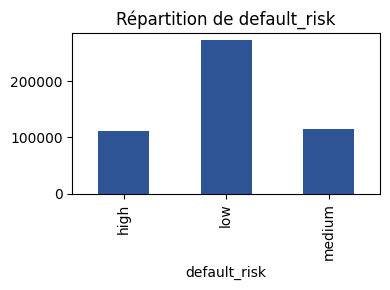

In [6]:
y_raw = df[TARGET]
vc = y_raw.value_counts(dropna=False)
display(pd.DataFrame({"effectif": vc, "proportion": (vc / n).round(4)}))
classes = sorted(y_raw.dropna().unique().tolist(), key=str)
n_classes = len(classes)
is_binary = n_classes == 2
imbalance = float(vc.max() / vc.min())
print(f"dtype : {y_raw.dtype} | {n_classes} classes : {classes} | valeurs manquantes : {int(y_raw.isna().sum())}")
print(f"Rapport classe majoritaire / minoritaire : {imbalance:.2f}")
print("Type de problème :", "classification binaire" if is_binary else f"classification multiclasse ({n_classes} classes)")
Y = {k: (y_raw == k).astype(int) for k in classes}
fig, ax = plt.subplots(figsize=(4, 3))
vc.sort_index().plot.bar(ax=ax, color="#2F5496"); ax.set_title("Répartition de " + TARGET)
plt.tight_layout(); plt.savefig(FIG / "target_distribution.png", dpi=150); plt.show()

## 4. Typage des variables
Séparation en numériques et catégorielles (la cible est exclue).

In [7]:
drop_cols = sorted(set(ident_like + constantes))
print("Colonnes écartées de l'analyse (identifiants, constantes) :", drop_cols)
features = [c for c in df.columns if c != TARGET and c not in drop_cols]
num_cols = [c for c in features if pd.api.types.is_numeric_dtype(df[c]) and not pd.api.types.is_bool_dtype(df[c])]
bool_cols = [c for c in features if pd.api.types.is_bool_dtype(df[c])]
cat_cols = [c for c in features if c not in num_cols + bool_cols]
print("Numériques :", num_cols)
print("Booléennes :", bool_cols)
print("Catégorielles :", cat_cols)

Colonnes écartées de l'analyse (identifiants, constantes) : ['assessment_date', 'customer_id', 'phone_number']
Numériques : ['credit_score', 'tenure_months', 'avg_monthly_spend_ngn', 'recharge_frequency_per_month', 'payment_consistency_score', 'late_payment_count', 'max_loan_amount_ngn']
Booléennes : ['loan_eligibility']
Catégorielles : ['operator', 'credit_rating', 'account_type']


## 5. Variables numériques : distribution, asymétrie, valeurs extrêmes

,count,mean,std,min,25%,50%,75%,max,asymétrie,"% hors 1,5 IQR"
credit_score,500000.0,753.096,194.630,300.00,608.000,769.00,931.000,1000.00,-0.396,0.00
tenure_months,500000.0,60.517,34.601,1.00,31.000,60.00,90.000,120.00,0.001,0.00
avg_monthly_spend_ngn,500000.0,25239.787,14287.841,500.05,12836.598,25226.36,37601.825,49999.93,0.000,0.00
recharge_frequency_per_month,500000.0,15.481,8.656,1.00,8.000,15.00,23.000,30.00,0.001,0.00
payment_consistency_score,500000.0,0.500,0.288,0.00,0.250,0.50,0.750,1.00,0.001,0.00
late_payment_count,500000.0,2.242,2.644,0.00,0.000,1.00,2.000,10.00,1.578,14.11
max_loan_amount_ngn,500000.0,37001.947,36683.638,0.00,0.000,30254.49,62228.398,149588.33,0.727,0.00


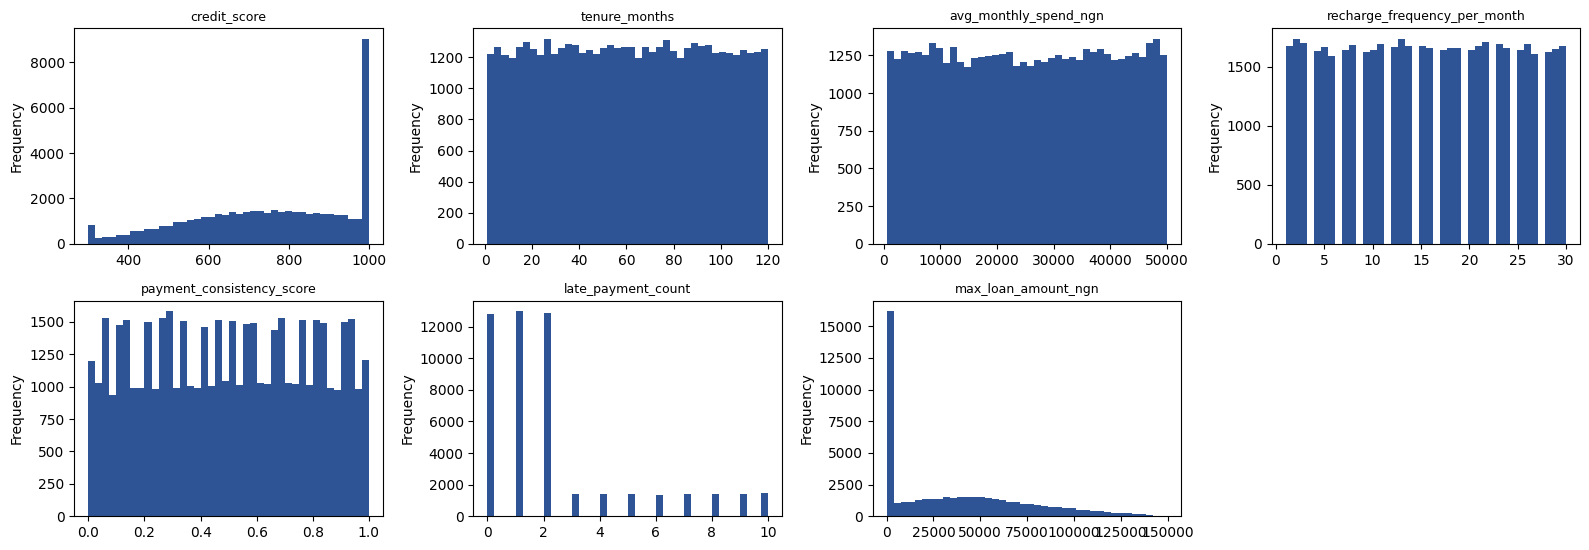

In [8]:
if num_cols:
    desc = df[num_cols].describe().T
    desc["asymétrie"] = df[num_cols].skew()
    q1, q3 = df[num_cols].quantile(0.25), df[num_cols].quantile(0.75)
    iqr = q3 - q1
    desc["% hors 1,5 IQR"] = (((df[num_cols] < q1 - 1.5 * iqr) | (df[num_cols] > q3 + 1.5 * iqr)).mean() * 100).round(2)
    display(desc.round(3))
    k = len(num_cols); cols = 4; rows = int(np.ceil(k / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 2.8 * rows)); axes = np.array(axes).ravel()
    for ax, c in zip(axes, num_cols):
        (lambda s: s.sample(min(50000, len(s)), random_state=0))(df[c].dropna()).plot.hist(bins=40, ax=ax, color="#2F5496"); ax.set_title(c, fontsize=9)
    for ax in axes[k:]: ax.axis("off")
    plt.tight_layout(); plt.savefig(FIG / "numeric_distributions.png", dpi=130); plt.show()

## 6. Variables catégorielles

In [9]:
for c in cat_cols:
    print(f"--- {c} : {df[c].nunique()} modalités")
    display(df[c].value_counts(dropna=False).head(10).to_frame("effectif").assign(prop=lambda d: (d.effectif / n).round(4)))

--- operator : 4 modalités


,effectif,prop
operator,,
MTN,189846,0.3797
Airtel,140424,0.2808
Glo,120044,0.2401
9mobile,49686,0.0994


--- credit_rating : 4 modalités


,effectif,prop
credit_rating,,
excellent,224918,0.4498
good,119607,0.2392
fair,94890,0.1898
poor,60585,0.1212


--- account_type : 2 modalités


,effectif,prop
account_type,,
prepaid,425027,0.8501
postpaid,74973,0.1499


## 7. Lien avec la cible
- Variables numériques et booléennes : moyenne par classe et **AUC un-contre-tous** pour chaque classe (0,5 = aucune information ; proche de 1 = suspect, voir la section fuite de données).
- Variables catégorielles : répartition des classes de la cible par modalité.

In [10]:
rows = []
for c in num_cols + bool_cols:
    s_ = df[c].astype(float)
    ok = s_.notna()
    row = {"variable": c}
    aucs = []
    for k in classes:
        row[f"moy_{k}"] = s_[ok & (y_raw == k)].mean()
    for k in classes:
        a = roc_auc_score(Y[k][ok], s_[ok]); row[f"AUC_{k}"] = a; aucs.append(max(a, 1 - a))
    row["AUC_max"] = max(aucs)
    rows.append(row)
rel = pd.DataFrame(rows).set_index("variable").sort_values("AUC_max", ascending=False)
display(rel.round(4))
for c in cat_cols:
    if df[c].nunique() <= 30:
        print("---", c, ": répartition des classes par modalité")
        display(pd.crosstab(df[c], y_raw, normalize="index").round(4))

,moy_high,moy_low,moy_medium,AUC_high,AUC_low,AUC_medium,AUC_max
variable,,,,,,,
max_loan_amount_ngn,16265.5041,47573.5111,32018.9459,0.2523,0.7162,0.4397,0.7477
credit_score,620.1469,821.0741,720.6767,0.2532,0.7159,0.4392,0.7468
loan_eligibility,0.3055,0.8849,0.5962,0.2533,0.7156,0.4396,0.7467
tenure_months,42.5663,69.6596,56.2231,0.3073,0.6679,0.4534,0.6927
late_payment_count,3.7808,1.4578,2.6105,0.6800,0.3431,0.5435,0.6800
recharge_frequency_per_month,13.4133,16.5348,14.9842,0.4114,0.5773,0.4785,0.5886
payment_consistency_score,0.4313,0.5349,0.4820,0.4122,0.5778,0.4771,0.5878
avg_monthly_spend_ngn,23232.9551,26262.5020,24758.4378,0.4478,0.5455,0.4873,0.5522


--- operator : répartition des classes par modalité


default_risk,high,low,medium
operator,,,
9mobile,0.2222,0.5490,0.2288
Airtel,0.2250,0.5428,0.2323
Glo,0.2210,0.5479,0.2310
MTN,0.2219,0.5458,0.2323


--- credit_rating : répartition des classes par modalité


default_risk,high,low,medium
credit_rating,,,
excellent,0.0986,0.7011,0.2003
fair,0.4987,0.2016,0.2997
good,0.0987,0.7005,0.2007
poor,0.4948,0.2028,0.3025


--- account_type : répartition des classes par modalité


default_risk,high,low,medium
account_type,,,
postpaid,0.2208,0.5476,0.2316
prepaid,0.2229,0.5455,0.2317


## 8. Corrélations entre variables explicatives (multicolinéarité)

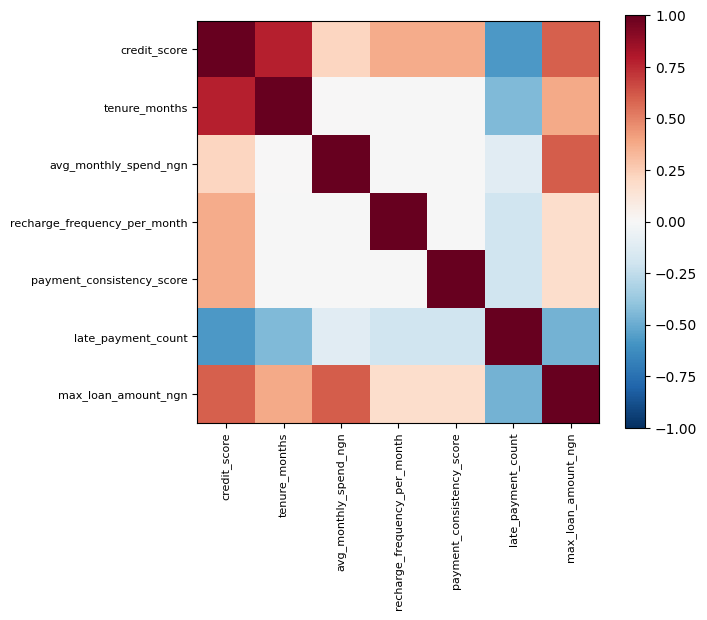

Paires très corrélées (|r| >= 0,8) : []


In [11]:
high_pairs = []
if len(num_cols) > 1:
    corr = df[num_cols].corr()
    fig, ax = plt.subplots(figsize=(0.6 * len(num_cols) + 3, 0.6 * len(num_cols) + 2))
    im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(num_cols))); ax.set_xticklabels(num_cols, rotation=90, fontsize=8)
    ax.set_yticks(range(len(num_cols))); ax.set_yticklabels(num_cols, fontsize=8)
    plt.colorbar(im); plt.tight_layout(); plt.savefig(FIG / "correlation_matrix.png", dpi=130); plt.show()
    for i, a in enumerate(num_cols):
        for b in num_cols[i + 1:]:
            if abs(corr.loc[a, b]) >= 0.8: high_pairs.append((a, b, round(float(corr.loc[a, b]), 3)))
print("Paires très corrélées (|r| >= 0,8) :", high_pairs)

## 9. Risques de fuite de données (*data leakage*)
Un indice de fuite n'est **pas** une preuve : une variable très prédictive peut être légitime. On liste les variables à examiner avec la définition métier (la valeur est-elle connue **avant** le moment de la prédiction ?).

Deux contrôles :
1. AUC un-contre-tous maximale de chaque variable (seuil d'attention : 0,90).
2. **Sonde à une variable** : un petit arbre de décision n'utilisant que cette variable. On compare son F1 macro à celui d'un modèle qui prédit toujours la classe majoritaire.

In [12]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score

suspects = rel.index[rel["AUC_max"] >= 0.90].tolist()
print("Variables à examiner (AUC un-contre-tous >= 0,90) :", suspects or "aucune")

probe_cols = num_cols + bool_cols + [c for c in cat_cols if df[c].nunique() <= 30]
sample = df.sample(min(100000, n), random_state=0)
ys = sample[TARGET]
rows = []
for c in probe_cols:
    X = pd.get_dummies(sample[[c]]).astype(float) if c in cat_cols else sample[[c]].astype(float)
    Xtr, Xte, ytr, yte = train_test_split(X.fillna(0), ys, test_size=0.3, random_state=0, stratify=ys)
    m = DecisionTreeClassifier(max_depth=4, random_state=0).fit(Xtr, ytr)
    rows.append({"variable": c, "F1_macro_1_variable": f1_score(yte, m.predict(Xte), average="macro")})
base_f1 = f1_score(yte, [ys.mode()[0]] * len(yte), average="macro")
probe = pd.DataFrame(rows).set_index("variable").sort_values("F1_macro_1_variable", ascending=False)
print(f"F1 macro de référence (toujours la classe majoritaire) : {base_f1:.4f}")
display(probe.round(4))
print("Colonnes de type identifiant à exclure du modèle :", ident_like or "aucune")

Variables à examiner (AUC un-contre-tous >= 0,90) : aucune
F1 macro de référence (toujours la classe majoritaire) : 0.2353


,F1_macro_1_variable
variable,
max_loan_amount_ngn,0.4547
loan_eligibility,0.4546
credit_rating,0.4546
credit_score,0.4543
late_payment_count,0.4222
tenure_months,0.3669
avg_monthly_spend_ngn,0.2359
recharge_frequency_per_month,0.2353
payment_consistency_score,0.2353


Colonnes de type identifiant à exclure du modèle : ['customer_id', 'phone_number']


### Points à examiner à la main (ne pas conclure sans la définition métier)
- `credit_score`, `credit_rating`, `loan_eligibility`, `max_loan_amount_ngn` : ces colonnes ressemblent à des **sorties d'un processus de scoring**. Sont-elles disponibles au moment où l'on prédit `default_risk` ? Si elles sont calculées à partir du même risque, les utiliser revient à prédire la cible avec une version de la cible.
- `customer_id` et `phone_number` : identifiants (données personnelles), à exclure du modèle.
- `assessment_date` : constante, sans information.
- Décision proposée : comparer deux jeux de variables (avec et sans les colonnes de scoring) et justifier le choix dans le rapport.

## 10. Synthèse écrite automatiquement

In [13]:
summary = {
    "fichier": str(DATA_PATH.name), "lignes": int(n), "colonnes": int(df.shape[1]),
    "cible": TARGET, "classes": [str(k) for k in classes], "cible_binaire": bool(is_binary),
    "proportions_classes": {str(k): round(float(v), 4) for k, v in (vc / n).items()}, "rapport_majoritaire_minoritaire": round(imbalance, 2),
        "doublons": n_dup, "colonnes_constantes": constantes, "colonnes_identifiants": ident_like,
    "numeriques": num_cols, "categorielles": cat_cols, "booleennes": bool_cols,
    "colonnes_avec_manquants": quality.index[quality["manquants"] > 0].tolist(),
    "paires_correlees_0.8": high_pairs, "variables_a_examiner_fuite": suspects,
}
(ROOT / "reports").mkdir(exist_ok=True)
(ROOT / "reports/eda_summary.json").write_text(json.dumps(summary, indent=2, ensure_ascii=False), encoding="utf-8")
lines = ["# Résumé de l'exploration (généré par notebooks/01_eda.ipynb)", "",
         f"- Fichier : `{summary['fichier']}`", f"- Dimensions : {n} lignes, {df.shape[1]} colonnes",
         f"- Cible : `{TARGET}` ({n_classes} classes : {', '.join(str(k) + ' ' + format(v, '.1%') for k, v in (vc / n).items())})",
         f"- Doublons : {n_dup}", f"- Colonnes avec valeurs manquantes : {summary['colonnes_avec_manquants'] or 'aucune'}",
         f"- Colonnes constantes : {constantes or 'aucune'}", f"- Colonnes de type identifiant : {ident_like or 'aucune'}",
         f"- Variables numériques ({len(num_cols)}) : {', '.join(num_cols)}",
         f"- Variables catégorielles ({len(cat_cols)}) : {', '.join(cat_cols) or 'aucune'}",
         f"- Paires très corrélées : {high_pairs or 'aucune'}",
         f"- Variables à examiner (AUC un-contre-tous >= 0,90) : {suspects or 'aucune'} (voir aussi la sonde à une variable)", "",
         "## À compléter à la main", "- Description métier de chaque colonne (voir la fiche du dataset Hugging Face)",
         "- Décisions de prétraitement justifiées (manquants, valeurs extrêmes, encodage)",
         "- Licence et nature du jeu (synthétique ou réel)"]
(ROOT / "docs/eda_resume.md").write_text("\n".join(lines), encoding="utf-8")
print("\n".join(lines))

# Résumé de l'exploration (généré par notebooks/01_eda.ipynb)

- Fichier : `telecom.csv`
- Dimensions : 500000 lignes, 15 colonnes
- Cible : `default_risk` (3 classes : low 54.6%, medium 23.2%, high 22.3%)
- Doublons : 0
- Colonnes avec valeurs manquantes : aucune
- Colonnes constantes : ['assessment_date']
- Colonnes de type identifiant : ['customer_id', 'phone_number']
- Variables numériques (7) : credit_score, tenure_months, avg_monthly_spend_ngn, recharge_frequency_per_month, payment_consistency_score, late_payment_count, max_loan_amount_ngn
- Variables catégorielles (3) : operator, credit_rating, account_type
- Paires très corrélées : aucune
- Variables à examiner (AUC un-contre-tous >= 0,90) : aucune (voir aussi la sonde à une variable)

## À compléter à la main
- Description métier de chaque colonne (voir la fiche du dataset Hugging Face)
- Décisions de prétraitement justifiées (manquants, valeurs extrêmes, encodage)
- Licence et nature du jeu (synthétique ou réel)
